Nhóm 4_Nhận diện khuôn mặt;
9_Nguyễn Công Đại_232532833_XDDD&CN1;
13_Lê Hồng Dũng_232532817_XDDD&CN1;
19_Trần Đức Hiếu_232532865_XDDD&CN1;
28_Chu Minh Huy_232532885_XDDD&CN1;
29_Lê Quốc Huy_232532886_XDDD&CN1

In [16]:
print('hello world')

hello world


Cài đặt thư viện và kết nối Google Drive

In [1]:
# 1. Cài đặt các thư viện phụ thuộc trước
!pip install --upgrade pip setuptools wheel
!pip install mtcnn opencv-python-headless scikit-learn pandas matplotlib

# 2. Cài đặt facenet-pytorch nhưng bỏ qua kiểm tra dependencies cũ bằng --no-deps
!pip install --no-deps facenet-pytorch

# 3. Kết nối Google Drive
from google.colab import drive
drive.mount('/content/drive')

# 4. Kiểm tra thiết bị chạy
import torch
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Đang sử dụng thiết bị:', device)


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.9/1.9 MB 10.6 MB/s  0:00:00
Mounted at /content/drive
Đang sử dụng thiết bị: cuda


Trích xuất đặc trưng khuôn mặt

In [2]:
import os
import cv2
import torch
import numpy as np
import pandas as pd
from PIL import Image
from facenet_pytorch import MTCNN, InceptionResnetV1
import pickle

csv_path = '/content/drive/MyDrive/Nhóm 4 ( Nhận diện khuôn mặt)/members.csv'
base_dir = os.path.dirname(csv_path)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
mtcnn = MTCNN(image_size=160, margin=20, keep_all=False, device=device)
resnet = InceptionResnetV1(pretrained='vggface2').eval().to(device)

members_df = pd.read_csv(csv_path)

embedding_dict = {}

print("Bắt đầu quá trình trích xuất embedding khuôn mặt...\n")

for index, row in members_df.iterrows():
    mssv = str(row['mssv'])
    ho_ten = row['ho_ten']
    # Ép kiểu string tuyệt đối để tránh lỗi float khi đọc từ csv
    rel_folder = str(row['thu_muc_anh']).strip()
    folder_path = os.path.join(base_dir, rel_folder)

    embeddings = []
    if os.path.exists(folder_path):
        img_list = os.listdir(folder_path)
        for img_name in img_list:
            img_path = os.path.join(folder_path, img_name)
            try:
                img = Image.open(img_path).convert('RGB')
                face = mtcnn(img)
                if face is not None:
                    face_tensor = face.unsqueeze(0).to(device)
                    embedding = resnet(face_tensor).detach().cpu().numpy()[0]
                    embeddings.append(embedding)
            except Exception as e:
                print(f"Lỗi khi đọc ảnh {img_path}: {e}")

        if len(embeddings) > 0:
            mean_embedding = np.mean(embeddings, axis=0)
            embedding_dict[mssv] = mean_embedding
            print(f"✔ Đã xử lý xong: {ho_ten} (MSSV: {mssv}) - Số ảnh hợp lệ: {len(embeddings)}")
        else:
            print(f"⚠ Không tìm thấy ảnh hợp lệ cho: {ho_ten} (MSSV: {mssv})")
    else:
        print(f"❌ Không tìm thấy thư mục: {folder_path}")

# Lưu file embedding vào thư mục models trên Google Drive
model_dir = os.path.join(base_dir, 'models')
os.makedirs(model_dir, exist_ok=True)
model_path = os.path.join(model_dir, 'member_embeddings.pkl')

with open(model_path, 'wb') as f:
    pickle.dump(embedding_dict, f)

print(f"\n🎉 Hoàn thành! Đã lưu file embedding tại: {model_path}")

  0%|          | 0.00/107M [00:00<?, ?B/s]

Bắt đầu quá trình trích xuất embedding khuôn mặt...

✔ Đã xử lý xong: Le Quoc Huy (MSSV: 232532886.0) - Số ảnh hợp lệ: 30
✔ Đã xử lý xong: Nguyen Cong Dai (MSSV: 232532833.0) - Số ảnh hợp lệ: 30
✔ Đã xử lý xong: Le Hong Dung (MSSV: 232532817.0) - Số ảnh hợp lệ: 30
✔ Đã xử lý xong: Chu Minh Huy (MSSV: 232532885.0) - Số ảnh hợp lệ: 30
✔ Đã xử lý xong: Tran ?uc Hieu (MSSV: 232532865.0) - Số ảnh hợp lệ: 29
❌ Không tìm thấy thư mục: /content/drive/MyDrive/Nhóm 4 ( Nhận diện khuôn mặt)/nan
❌ Không tìm thấy thư mục: /content/drive/MyDrive/Nhóm 4 ( Nhận diện khuôn mặt)/nan
❌ Không tìm thấy thư mục: /content/drive/MyDrive/Nhóm 4 ( Nhận diện khuôn mặt)/nan
❌ Không tìm thấy thư mục: /content/drive/MyDrive/Nhóm 4 ( Nhận diện khuôn mặt)/nan
❌ Không tìm thấy thư mục: /content/drive/MyDrive/Nhóm 4 ( Nhận diện khuôn mặt)/nan
❌ Không tìm thấy thư mục: /content/drive/MyDrive/Nhóm 4 ( Nhận diện khuôn mặt)/nan
❌ Không tìm thấy thư mục: /content/drive/MyDrive

Khởi tạo hệ thống và định nghĩa hàm nhận diện

In [3]:
import os
import torch
import numpy as np
import pandas as pd
from PIL import Image
from facenet_pytorch import MTCNN, InceptionResnetV1
import torch.nn.functional as F
import pickle

# 1. Đường dẫn tự động tìm thư mục dự án trên Drive
base_dir = None
for root, dirs, files in os.walk('/content/drive/MyDrive'):
    if 'members.csv' in files:
        base_dir = root
        break

csv_path = os.path.join(base_dir, 'members.csv')
members_df = pd.read_csv(csv_path).dropna(subset=['mssv', 'thu_muc_anh'])

# 2. Load lại file model embedding đã lưu ở bước trước
model_path = os.path.join(base_dir, 'models', 'member_embeddings.pkl')
with open(model_path, 'rb') as f:
    embedding_dict = pickle.load(f)

# 3. Khởi tạo lại thiết bị và mô hình AI
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
mtcnn = MTCNN(image_size=160, margin=20, keep_all=False, device=device)
resnet = InceptionResnetV1(pretrained='vggface2').eval().to(device)

print("Đã sẵn sàng hệ thống nhận diện khuôn mặt!")

# 4. Định nghĩa hàm nhận diện khuôn mặt (với ngưỡng threshold)
def recognize_face(img_path, threshold=0.6):
    """
    Hàm nhận diện khuôn mặt:
    - Nếu độ tương đồng cosine >= threshold -> Hiển thị tên, MSSV, lớp (Thành viên nhóm).
    - Nếu < threshold -> Báo 'Không nhận ra' (Người lạ).
    """
    try:
        img = Image.open(img_path).convert('RGB')
        face = mtcnn(img)

        if face is None:
            return "Không tìm thấy khuôn mặt trong ảnh", 0.0

        face_tensor = face.unsqueeze(0).to(device)
        query_embedding = resnet(face_tensor).detach().cpu()

        max_similarity = -1
        best_match_mssv = None

        # So sánh cosine similarity với từng thành viên trong CSDL
        for mssv, emb in embedding_dict.items():
            emb_tensor = torch.tensor(emb).unsqueeze(0)
            sim = F.cosine_similarity(query_embedding, emb_tensor).item()
            if sim > max_similarity:
                max_similarity = sim
                best_match_mssv = mssv

        # Kiểm tra với ngưỡng (threshold) đã chọn
        if max_similarity >= threshold:
            member_info = members_df[members_df['mssv'].astype(str).str.contains(str(best_match_mssv))].iloc[0]
            result = f"{member_info['ho_ten']} - {member_info['mssv']} - {member_info['lop']}"
            return result, max_similarity
        else:
            return "Không nhận ra (Người lạ)", max_similarity

    except Exception as e:
        return f"Lỗi xử lý ảnh: {e}", 0.0

Đã sẵn sàng hệ thống nhận diện khuôn mặt!


Xây dựng hàm đánh giá mô hình

In [4]:
import os
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report

def evaluate_model(threshold=0.6):
    y_true = []
    y_pred = []

    test_dir = os.path.join(base_dir, 'data', 'test')
    unknown_dir = os.path.join(base_dir, 'data', 'unknown')

    print(f"Đang đánh giá mô hình với Threshold = {threshold}...\n")

    # 1. Đánh giá ảnh của các thành viên trong thư mục test/
    if os.path.exists(test_dir):
        for mssv_folder in os.listdir(test_dir):
            folder_path = os.path.join(test_dir, mssv_folder)
            if os.path.isdir(folder_path):
                for img_name in os.listdir(folder_path):
                    img_path = os.path.join(folder_path, img_name)
                    if os.path.isfile(img_path):
                        result, score = recognize_face(img_path, threshold=threshold)

                        y_true.append(str(mssv_folder)) # Nhãn thực tế là MSSV của thư mục

                        # Kiểm tra nếu kết quả trả về hợp lệ chứa dấu ' - '
                        if " - " in result:
                            parts = result.split(' - ')
                            if len(parts) >= 2:
                                y_pred.append(str(parts[1]))
                            else:
                                y_pred.append("Unknown")
                        else:
                            y_pred.append("Unknown")

    # 2. Đánh giá ảnh người lạ trong thư mục unknown/
    if os.path.exists(unknown_dir):
        for img_name in os.listdir(unknown_dir):
            img_path = os.path.join(unknown_dir, img_name)
            if os.path.isfile(img_path):
                result, score = recognize_face(img_path, threshold=threshold)
                y_true.append("Unknown") # Nhãn thực tế là người lạ

                if " - " in result:
                    parts = result.split(' - ')
                    if len(parts) >= 2:
                        y_pred.append(str(parts[1]))
                    else:
                        y_pred.append("Unknown")
                else:
                    y_pred.append("Unknown")

    print("Hoàn thành quét dữ liệu kiểm thử!")
    return y_true, y_pred

# Chạy lại đánh giá
y_true, y_pred = evaluate_model(threshold=0.6)

Đang đánh giá mô hình với Threshold = 0.6...

Hoàn thành quét dữ liệu kiểm thử!


Trực quan hóa kết quả đánh giá

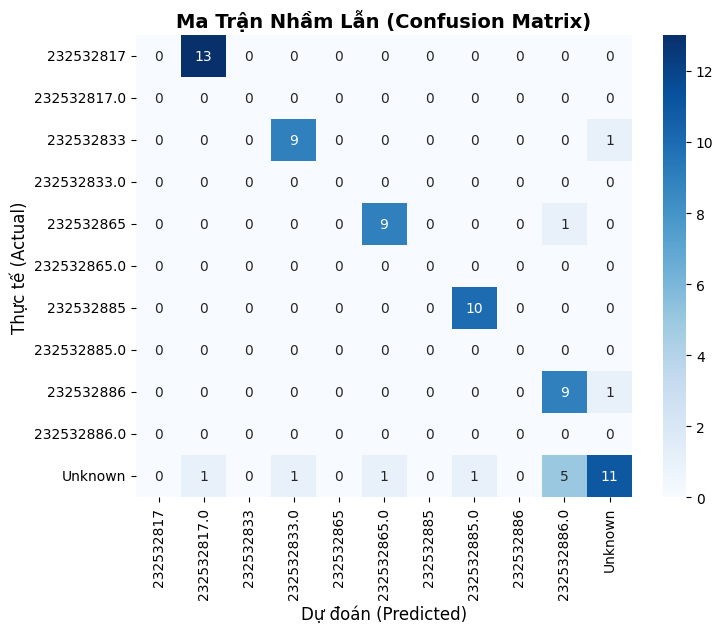


Báo cáo chi tiết (Classification Report):
              precision    recall  f1-score   support

   232532817       0.00      0.00      0.00        13
 232532817.0       0.00      0.00      0.00         0
   232532833       0.00      0.00      0.00        10
 232532833.0       0.00      0.00      0.00         0
   232532865       0.00      0.00      0.00        10
 232532865.0       0.00      0.00      0.00         0
   232532885       0.00      0.00      0.00        10
 232532885.0       0.00      0.00      0.00         0
   232532886       0.00      0.00      0.00        10
 232532886.0       0.00      0.00      0.00         0
     Unknown       0.85      0.55      0.67        20

    accuracy                           0.15        73
   macro avg       0.08      0.05      0.06        73
weighted avg       0.23      0.15      0.18        73



In [5]:

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report

# Lọc các nhãn xuất hiện trong dữ liệu thực tế và dự đoán
labels = sorted(list(set(y_true + y_pred)))
cm = confusion_matrix(y_true, y_pred, labels=labels)

# Vẽ biểu đồ Ma trận nhầm lẫn
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=labels, yticklabels=labels)
plt.xlabel('Dự đoán (Predicted)', fontsize=12)
plt.ylabel('Thực tế (Actual)', fontsize=12)
plt.title('Ma Trận Nhầm Lẫn (Confusion Matrix)', fontsize=14, fontweight='bold')
plt.show()

# In báo cáo chi tiết độ chính xác (Accuracy, Precision, Recall, F1-Score)
print("\nBáo cáo chi tiết (Classification Report):")
print(classification_report(y_true, y_pred, zero_division=0))

Cải tiến và làm sạch nhãn đánh giá

Đang đánh giá lại mô hình với Threshold = 0.6...

Hoàn thành đánh giá!


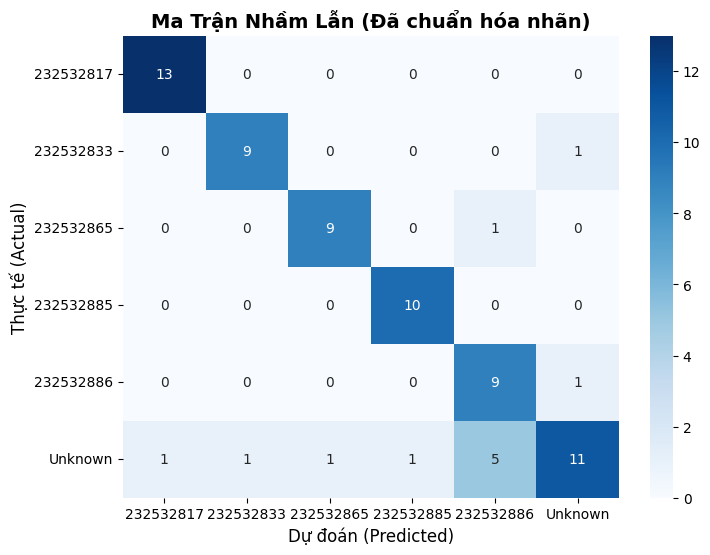


Báo cáo chi tiết (Classification Report):
              precision    recall  f1-score   support

   232532817       0.93      1.00      0.96        13
   232532833       0.90      0.90      0.90        10
   232532865       0.90      0.90      0.90        10
   232532885       0.91      1.00      0.95        10
   232532886       0.60      0.90      0.72        10
     Unknown       0.85      0.55      0.67        20

    accuracy                           0.84        73
   macro avg       0.85      0.88      0.85        73
weighted avg       0.85      0.84      0.83        73



In [6]:

import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report

def evaluate_model_fixed(threshold=0.6):
    y_true = []
    y_pred = []

    test_dir = os.path.join(base_dir, 'data', 'test')
    unknown_dir = os.path.join(base_dir, 'data', 'unknown')

    print(f"Đang đánh giá lại mô hình với Threshold = {threshold}...\n")

    # 1. Đánh giá tập test (thành viên)
    if os.path.exists(test_dir):
        for mssv_folder in os.listdir(test_dir):
            folder_path = os.path.join(test_dir, mssv_folder)
            if os.path.isdir(folder_path):
                # Làm sạch nhãn MSSV (bỏ phần .0 nếu có)
                clean_true_mssv = str(mssv_folder).split('.')[0].strip()

                for img_name in os.listdir(folder_path):
                    img_path = os.path.join(folder_path, img_name)
                    if os.path.isfile(img_path):
                        result, score = recognize_face(img_path, threshold=threshold)
                        y_true.append(clean_true_mssv)

                        if " - " in result:
                            parts = result.split(' - ')
                            if len(parts) >= 2:
                                clean_pred_mssv = str(parts[1]).split('.')[0].strip()
                                y_pred.append(clean_pred_mssv)
                            else:
                                y_pred.append("Unknown")
                        else:
                            y_pred.append("Unknown")

    # 2. Đánh giá tập unknown (người lạ)
    if os.path.exists(unknown_dir):
        for img_name in os.listdir(unknown_dir):
            img_path = os.path.join(unknown_dir, img_name)
            if os.path.isfile(img_path):
                result, score = recognize_face(img_path, threshold=threshold)
                y_true.append("Unknown")

                if " - " in result:
                    parts = result.split(' - ')
                    if len(parts) >= 2:
                        clean_pred_mssv = str(parts[1]).split('.')[0].strip()
                        y_pred.append(clean_pred_mssv)
                    else:
                        y_pred.append("Unknown")
                else:
                    y_pred.append("Unknown")

    print("Hoàn thành đánh giá!")
    return y_true, y_pred

# Chạy lại với threshold = 0.55 hoặc 0.6 (Bạn có thể đổi số này từ 0.5 đến 0.7 để test)
y_true_fix, y_pred_fix = evaluate_model_fixed(threshold=0.6)

# Vẽ lại Ma trận nhầm lẫn sạch sẽ
labels = sorted(list(set(y_true_fix + y_pred_fix)))
cm = confusion_matrix(y_true_fix, y_pred_fix, labels=labels)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=labels, yticklabels=labels)
plt.xlabel('Dự đoán (Predicted)', fontsize=12)
plt.ylabel('Thực tế (Actual)', fontsize=12)
plt.title('Ma Trận Nhầm Lẫn (Đã chuẩn hóa nhãn)', fontsize=14, fontweight='bold')
plt.show()

print("\nBáo cáo chi tiết (Classification Report):")
print(classification_report(y_true_fix, y_pred_fix, zero_division=0))

Chạy đánh giá với Threshold = 0.6

In [7]:
y_true_fix, y_pred_fix = evaluate_model_fixed(threshold=0.65)


Đang đánh giá lại mô hình với Threshold = 0.65...

Hoàn thành đánh giá!


Tinh chỉnh ngưỡng Threshold = 0.65

In [8]:

from sklearn.metrics import classification_report
print("Báo cáo chi tiết với Threshold = 0.65:")
print(classification_report(y_true_fix, y_pred_fix, zero_division=0))

Báo cáo chi tiết với Threshold = 0.65:
              precision    recall  f1-score   support

   232532817       0.93      1.00      0.96        13
   232532833       1.00      0.90      0.95        10
   232532865       1.00      0.80      0.89        10
   232532885       0.91      1.00      0.95        10
   232532886       0.69      0.90      0.78        10
     Unknown       0.83      0.75      0.79        20

    accuracy                           0.88        73
   macro avg       0.89      0.89      0.89        73
weighted avg       0.89      0.88      0.88        73



Đồng bộ hóa dữ liệu từ Google Drive

In [14]:
from google.colab import drive
import os
import shutil

# 1. Kết nối Google Drive
drive.mount('/content/drive')

# 2. Tự động tìm và copy members.csv cùng thư mục models về thư mục hiện tại
for root, dirs, files in os.walk('/content/drive/MyDrive'):
    if 'members.csv' in files:
        shutil.copy(os.path.join(root, 'members.csv'), '.')
        models_dir = os.path.join(root, 'models')
        if os.path.exists(models_dir):
            shutil.copytree(models_dir, 'models', dirs_exist_ok=True)
        print("✔ Đã đồng bộ thành công members.csv và models từ Google Drive!")
        break

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
✔ Đã đồng bộ thành công members.csv và models từ Google Drive!


Nhận diện khuôn mặt thời gian thực qua Webcam

⏳ Đang tải mô hình và dữ liệu...
📷 Vui lòng bấm nút 'Chụp ảnh' bên dưới...


<IPython.core.display.Javascript object>

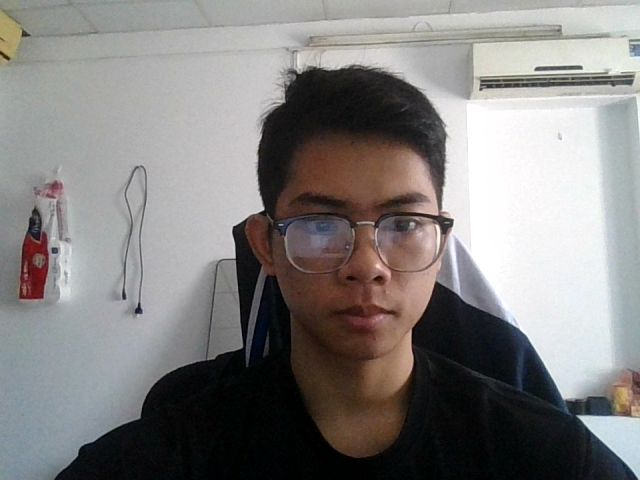

In [15]:
from IPython.display import display, Javascript, HTML, Image as IPyImage
from google.colab.output import eval_js
from base64 import b64decode
import os
import torch
import torch.nn.functional as F
from PIL import Image
from facenet_pytorch import MTCNN, InceptionResnetV1
import pickle
import pandas as pd

def take_photo(filename='webcam_capture.jpg', quality=0.8):
    js = Javascript('''
        async function takePhoto(quality) {
            const div = document.createElement('div');
            const capture = document.createElement('button');
            capture.textContent = '📸 Chụp ảnh (Capture)';
            capture.style.padding = '10px 20px';
            capture.style.fontSize = '16px';
            capture.style.backgroundColor = '#4CAF50';
            capture.style.color = 'white';
            capture.style.border = 'none';
            capture.style.borderRadius = '5px';
            capture.style.cursor = 'pointer';
            div.appendChild(capture);

            const video = document.createElement('video');
            video.style.display = 'block';
            const stream = await navigator.mediaDevices.getUserMedia({video: { facingMode: "user" }});

            document.body.appendChild(div);
            div.appendChild(video);
            video.srcObject = stream;
            await video.play();

            google.colab.output.setIframeHeight(document.documentElement.scrollHeight, true);

            await new Promise((resolve) => capture.onclick = resolve);

            const canvas = document.createElement('canvas');
            canvas.width = video.videoWidth;
            canvas.height = video.videoHeight;
            canvas.getContext('2d').drawImage(video, 0, 0);
            stream.getVideoTracks()[0].stop();
            div.remove();
            return canvas.toDataURL('image/jpeg', quality);
        }
    ''')
    display(js)
    data = eval_js('takePhoto({})'.format(quality))
    binary = b64decode(data.split(',')[1])
    with open(filename, 'wb') as f:
        f.write(binary)
    return filename

def recognize_webcam():
    print("⏳ Đang tải mô hình và dữ liệu...")
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    mtcnn = MTCNN(image_size=160, margin=20, keep_all=False, device=device)
    resnet = InceptionResnetV1(pretrained='vggface2').eval().to(device)

    try:
        members_df = pd.read_csv('members.csv')
        with open('models/member_embeddings.pkl', 'rb') as f:
            embedding_dict = pickle.load(f)
    except Exception as e:
        print(f"Lỗi tải dữ liệu hoặc mô hình: {e}")
        return

    print("📷 Vui lòng bấm nút 'Chụp ảnh' bên dưới...")
    try:
        img_path = take_photo('webcam_capture.jpg')

        img = Image.open(img_path).convert('RGB')
        face = mtcnn(img)
        if face is None:
            display(HTML("<h3 style='color:red; font-weight:bold;'>Không tìm thấy khuôn mặt trong ảnh từ webcam!</h3>"))
            display(IPyImage(img_path))
            return

        face_tensor = face.unsqueeze(0).to(device)
        query_embedding = resnet(face_tensor).detach().cpu()

        max_similarity = -1
        best_match_mssv = None

        for mssv, emb in embedding_dict.items():
            emb_tensor = torch.tensor(emb).unsqueeze(0)
            sim = F.cosine_similarity(query_embedding, emb_tensor).item()
            if sim > max_similarity:
                max_similarity = sim
                best_match_mssv = mssv

        threshold = 0.65

        # Hiển thị kết quả dạng chữ to, đậm màu Xanh hoặc Đỏ giống mẫu của bạn
        if max_similarity >= threshold:
            member_info = members_df[members_df['mssv'].astype(str).str.contains(str(best_match_mssv))].iloc[0]
            html_result = f"""
            <div style="font-family: sans-serif; margin-top: 10px;">
                <h2 style="color: green; font-weight: bold; margin-bottom: 5px;">KẾT QUẢ: {member_info['ho_ten']} - {member_info['mssv']} - {member_info['lop']}</h2>
                <h3 style="color: green; font-weight: bold; margin-top: 0;">Độ tương đồng: {max_similarity:.2f}</h3>
            </div>
            """
        else:
            html_result = f"""
            <div style="font-family: sans-serif; margin-top: 10px;">
                <h2 style="color: red; font-weight: bold; margin-bottom: 5px;">KẾT QUẢ: Không nhận ra (Người lạ)</h2>
                <h3 style="color: red; font-weight: bold; margin-top: 0;">Độ tương đồng: {max_similarity:.2f}</h3>
            </div>
            """

        display(HTML(html_result))
        display(IPyImage(img_path))

    except Exception as e:
        print(f"Lỗi: {e}")

recognize_webcam()